# Checks (Alaska, Sentinel-1): coherence loss / phase closure vs. soil-moisture differences

Same sanity check as [`Checks_alaska.ipynb`](Checks_alaska.ipynb) (the De Zan
model's core assumption: coherence loss between two acquisitions should track
the real soil-moisture *difference* between them, and phase closure magnitude
should track the SM *range* across a triplet) -- but for the **Sentinel-1**
coherence/closure-phase CSVs from
[`S1_coh_phase_closure.ipynb`](S1_coh_phase_closure.ipynb)
(`S1_coherence_closure_alaska/{station}_orbit{orbit}_S1_coherence.csv` /
`_S1_closure_phase.csv`) instead of NISAR's.

Uses the same in-situ SNOTEL/USCRN soil-moisture series and interpolation as
`Checks_alaska.ipynb`, and compares both 5cm and 20cm depth.

**Differences from `Checks_alaska.ipynb`**, driven by real differences in the S1
pipeline, not stylistic choices:
- **One file per (station, orbit), not one per station.** NISAR's coherence CSV
  already has every track pooled into one file per station (`orbit_num` column);
  S1's are written one file per kept (station, orbit) combination, so this
  notebook globs and concatenates them per station instead of reading a single
  file. `S1_coh_phase_closure.ipynb`'s HyP3 batch may still be running when
  this is run -- a `NaN` `coherence_VV`/`closure_phase_VV` means that pair's
  job hasn't finished (or failed) yet, not a data problem; re-run this notebook
  after more jobs complete to pick up more rows.
- **VV only, no polarization comparison.** These bursts are single-pol VV
  (matching `S1_burst_stations.ipynb`'s own `polarization=asf.POLARIZATION.VV`
  search filter), so there's no HH/HV split to make -- unlike NISAR's dual/
  quad-pol GSLC data.
- **Full pairwise matrix already.** `S1_coh_phase_closure.ipynb` submits every
  `N(N-1)/2` pair per (station, orbit) (matching `NISAR_SM.ipynb`'s own
  full-matrix approach, not a reduced sequential-only set), so every triplet
  `C(N,3)` is already reported here -- nothing extra to change on that front.

In [1]:
import sys
import os
from pathlib import Path

import pyproj
pyproj.datadir.set_data_dir(os.path.join(sys.prefix, "Library", "share", "proj"))


def require_globals(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            f"Missing {missing} -- run the earlier setup cells first "
            "(the kernel may have been restarted)."
        )


BASE = Path.cwd()
EARSEL_NOTEBOOKS = BASE / "Earsel26_NISAR-main" / "notebooks"
INSITU_DIR = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "station_data"
S1_COH_CLOSURE_DIR = BASE / "S1_coherence_closure_alaska"


C:\Users\geoka\miniconda3\envs\nisar-era5\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 1. In-situ SM reader and a generic bracket-interpolator

Identical to `Checks_alaska.ipynb` -- `{station}_ts_{depth}.csv` has irregular
timestamps (real sensor reporting times, not a fixed hourly grid), so
`interp_insitu_at` finds the nearest real reading before and after the target
time and linearly interpolates, returning NaN if there's no reading on one side
or the bracketing gap exceeds `MAX_GAP_HOURS`.

In [2]:
require_globals("INSITU_DIR")

import numpy as np
import pandas as pd

MAX_GAP_HOURS = 6
DEPTH_MAIN = 0.05
DEPTH_SECONDARY = 0.20

JUMP_THRESHOLD = 0.08  # 8 percentage points/hour -- real volumetric SM can't move this fast
FAULT_CEILING = 0.08   # a bracketed low plateau only counts as a fault if it stays this implausibly low throughout
MAX_BRIDGE_DAYS = 30
MIN_READINGS = 200     # RockyPoint's 20cm file has only 53 valid readings (every other station/depth has 1200-2255) -- too sparse to be a meaningful comparison

def read_insitu(station, depth):
    path = INSITU_DIR / f"{station}_ts_{depth:.2f}.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    series = df.iloc[:, 0].sort_index()  # single sm_<depth> column, whatever it's named

    # Sensor-fault plateaus (e.g. ImnaviatCreek 5cm 2026-07-23->08-03, stuck
    # near 0.1-0.2%; RockyPoint 5cm 2026-07-18->07-20, stuck near 1-5%) are
    # bracketed by physically impossible single-step jumps on both sides (real
    # volumetric SM can't move this fast) with an implausibly low interior
    # throughout -- mask everything between a big drop and the next big rise
    # that follows it, but only when that whole interior stays below
    # FAULT_CEILING. A fast-but-real wet-up/dry-down (e.g. EagleSummit's 20cm
    # 6-day dip to 14-19%) has the same jump signature but a physically
    # plausible interior, so it's left alone -- a plain magnitude threshold on
    # its own can't tell these apart (checked against every station/depth
    # here before picking these constants).
    diffs = series.diff()
    drops = series.index[diffs < -JUMP_THRESHOLD]
    rises = series.index[diffs > JUMP_THRESHOLD]
    for drop_ts in drops:
        later_rises = rises[rises > drop_ts]
        if len(later_rises) == 0:
            continue
        rise_ts = later_rises[0]
        if (rise_ts - drop_ts) > pd.Timedelta(days=MAX_BRIDGE_DAYS):
            continue
        span = series.loc[drop_ts:rise_ts].iloc[:-1]  # exclude the recovery reading itself
        if span.max() < FAULT_CEILING:
            series.loc[span.index] = np.nan

    # Exact 0.0 (or negative) is never a plausible reading on its own either,
    # even outside a bracketed fault window.
    series = series.mask(series <= 0)

    # Too few real readings to interpolate a meaningful comparison from (e.g.
    # RockyPoint's 20cm sensor) -- treat the same as "no data" rather than
    # feeding a handful of points into the comparison.
    if series.notna().sum() < MIN_READINGS:
        return None

    return series


def interp_insitu_at(series, ts):
    before = series.loc[:ts]
    after = series.loc[ts:]
    if before.empty or after.empty:
        return np.nan
    t0, v0 = before.index[-1], before.iloc[-1]
    t1, v1 = after.index[0], after.iloc[0]
    if t0 == t1:
        return float(v0)
    gap_hours = (t1 - t0).total_seconds() / 3600.0
    if gap_hours > MAX_GAP_HOURS:
        return np.nan
    frac = (ts - t0).total_seconds() / (t1 - t0).total_seconds()
    return float(v0 + frac * (v1 - v0))


## 2. Load the Sentinel-1 coherence and closure-phase CSVs

Discovers stations directly from `S1_coherence_closure_alaska/`'s filenames
(`{station}_orbit{orbit}_S1_coherence.csv`) rather than the full Alaska station
list, since only stations with at least one kept (station, orbit) combination
from `S1_burst_stations.ipynb` have any files here at all. Every orbit's file
for a station is concatenated into one table (the `orbit` column, already
present in each file, still identifies which track a row came from).

In [3]:
require_globals("S1_COH_CLOSURE_DIR")

import re

FILENAME_RE = re.compile(r"^(?P<station>.+)_orbit(?P<orbit>\d+)_S1_coherence\.csv$")
DATE_COLS_PAIRS = ["date_1", "date_2"]
DATE_COLS_TRIPLETS = ["date_1", "date_2", "date_3"]

station_orbits = {}  # station -> [orbit, ...]
for path in sorted(S1_COH_CLOSURE_DIR.glob("*_S1_coherence.csv")):
    m = FILENAME_RE.match(path.name)
    if not m:
        continue
    station_orbits.setdefault(m.group("station"), []).append(m.group("orbit"))

coherence_by_station = {}
closure_by_station = {}
for station, orbits in station_orbits.items():
    coh_parts, clo_parts = [], []
    for orbit in orbits:
        coh_path = S1_COH_CLOSURE_DIR / f"{station}_orbit{orbit}_S1_coherence.csv"
        clo_path = S1_COH_CLOSURE_DIR / f"{station}_orbit{orbit}_S1_closure_phase.csv"
        if not coh_path.exists() or not clo_path.exists():
            continue
        coh_parts.append(pd.read_csv(coh_path))
        clo_parts.append(pd.read_csv(clo_path))
    if not coh_parts:
        continue
    df_coh = pd.concat(coh_parts, ignore_index=True)
    df_clo = pd.concat(clo_parts, ignore_index=True)
    for col in DATE_COLS_PAIRS:
        df_coh[col] = pd.to_datetime(df_coh[col])
    for col in DATE_COLS_TRIPLETS:
        df_clo[col] = pd.to_datetime(df_clo[col])
    coherence_by_station[station] = df_coh
    closure_by_station[station] = df_clo
    n_coh_ready = df_coh["coherence_VV"].notna().sum()
    n_clo_ready = df_clo["closure_phase_VV"].notna().sum()
    print(f"{station}: {len(orbits)} orbit(s), {n_coh_ready}/{len(df_coh)} pair(s) ready, "
          f"{n_clo_ready}/{len(df_clo)} triplet(s) ready")


AtigunPass: 1 orbit(s), 15/15 pair(s) ready, 20/20 triplet(s) ready
Coldfoot: 1 orbit(s), 15/15 pair(s) ready, 20/20 triplet(s) ready
EagleSummit: 3 orbit(s), 36/36 pair(s) ready, 44/44 triplet(s) ready
GobblersKnob: 1 orbit(s), 15/15 pair(s) ready, 20/20 triplet(s) ready
GraniteCrk: 2 orbit(s), 21/21 pair(s) ready, 24/24 triplet(s) ready
ImnaviatCreek: 1 orbit(s), 15/15 pair(s) ready, 20/20 triplet(s) ready
Kenai-29-ENE: 1 orbit(s), 15/15 pair(s) ready, 20/20 triplet(s) ready
LittleChenaRidge: 2 orbit(s), 21/21 pair(s) ready, 24/24 triplet(s) ready
McGrath: 1 orbit(s), 6/6 pair(s) ready, 4/4 triplet(s) ready
NukaGlacier: 1 orbit(s), 6/6 pair(s) ready, 4/4 triplet(s) ready
PilgrimHotSprings: 1 orbit(s), 10/10 pair(s) ready, 10/10 triplet(s) ready
RockyPoint: 1 orbit(s), 10/10 pair(s) ready, 10/10 triplet(s) ready
SpringCreek: 2 orbit(s), 16/16 pair(s) ready, 14/14 triplet(s) ready
SusitnaValleyHigh: 1 orbit(s), 10/10 pair(s) ready, 10/10 triplet(s) ready
TurnagainPass: 1 orbit(s), 6/6 

## 3. Join against in-situ SM at a given depth

Same as `Checks_alaska.ipynb`: `|SM difference|` per pair, SM range
(`max - min`, requiring all three triplet readings to be valid) per triplet.
Also drops any pair/triplet with a same-pass-scale (`< MIN_BASELINE_DAYS`)
temporal baseline as a backup guard -- shouldn't trigger here in practice, since
`S1_burst_stations.ipynb`'s date matching already dedupes to one S1 acquisition
per calendar day per burst, but cheap insurance against the same class of bug
[`Checks_alaska.ipynb`](Checks_alaska.ipynb) found in the NISAR pipeline
(GraniteCrk tracks 87/92, same-pass adjacent-frame acquisitions seconds apart).

In [4]:
require_globals("coherence_by_station", "closure_by_station")

MIN_BASELINE_DAYS = 0.01  # ~14 minutes -- see the note above


def join_and_compare(depth):
    coherence_dfs = {}
    closure_dfs = {}
    for station in coherence_by_station:
        series = read_insitu(station, depth)
        if series is None:
            continue

        df_coh = coherence_by_station[station].copy()
        df_coh = df_coh[df_coh["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()
        df_coh["sm_1"] = df_coh["date_1"].apply(lambda ts: interp_insitu_at(series, ts)) * 100
        df_coh["sm_2"] = df_coh["date_2"].apply(lambda ts: interp_insitu_at(series, ts)) * 100
        df_coh["dsm"] = (df_coh["sm_1"] - df_coh["sm_2"]).abs()
        coherence_dfs[station] = df_coh

        df_clo = closure_by_station[station].copy()
        df_clo = df_clo[
            (df_clo["temporal_baseline_12_days"] >= MIN_BASELINE_DAYS)
            & (df_clo["temporal_baseline_23_days"] >= MIN_BASELINE_DAYS)
            & (df_clo["temporal_baseline_13_days"] >= MIN_BASELINE_DAYS)
        ].copy()
        for col in DATE_COLS_TRIPLETS:
            df_clo[f"sm_{col[-1]}"] = df_clo[col].apply(lambda ts: interp_insitu_at(series, ts)) * 100
        sm_cols = [f"sm_{col[-1]}" for col in DATE_COLS_TRIPLETS]
        # skipna=False: a triplet with only 2 of 3 in-situ readings shouldn't get
        # a "valid-looking" range computed from just those 2 -- the missing date
        # could be more extreme than either, so the true range is unknown, not
        # just narrower.
        df_clo["dsm_range"] = (
            df_clo[sm_cols].max(axis=1, skipna=False) - df_clo[sm_cols].min(axis=1, skipna=False)
        )
        df_clo["abs_closure_phase_VV"] = df_clo["closure_phase_VV"].abs()
        closure_dfs[station] = df_clo

    return coherence_dfs, closure_dfs


## 4. Plot helpers

Pooled across every kept orbit for a station (colored by `orbit`), same as
`Checks_alaska.ipynb`.

In [5]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm


def plot_coherence_vs_dsm(coherence_dfs, depth_label):
    station_list = list(coherence_dfs.keys())
    n_stations = len(station_list)
    ncols = 3
    nrows = int((n_stations + ncols - 1) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4))
    axes = axes.flatten()

    r_by_station = {}
    for idx, station in enumerate(station_list):
        ax = axes[idx]
        df_v = coherence_dfs[station]
        valid = df_v["coherence_VV"].notna() & df_v["dsm"].notna()
        df_v = df_v.loc[valid]
        x = df_v["dsm"].values
        y = df_v["coherence_VV"].values
        r = np.corrcoef(x, y)[0, 1] if len(x) > 1 else np.nan
        r_by_station[station] = r

        orbits = sorted(df_v["orbit"].unique())
        colors = cm.tab10(np.linspace(0, 1, max(len(orbits), 1)))
        for orbit, color in zip(orbits, colors):
            m = df_v["orbit"] == orbit
            ax.scatter(df_v.loc[m, "dsm"], df_v.loc[m, "coherence_VV"], color=color, s=40,
                       label=f"orbit {orbit}", zorder=3)
        if len(x) > 1:
            fit = np.polyfit(x, y, 1)
            xs = np.linspace(x.min(), x.max(), 10)
            ax.plot(xs, np.polyval(fit, xs), "--", color="firebrick", linewidth=1.5)
        ax.set_title(f"{station}\nR={r:.2f} (n={len(x)})")
        ax.set_xlabel("|SM difference| (%)")
        ax.set_ylabel("Coherence VV")
        ax.legend(fontsize=6, loc="best")
        ax.grid(True, alpha=0.3)

    for idx in range(n_stations, len(axes)):
        axes[idx].axis("off")

    plt.suptitle(f"Coherence (VV) vs. in-situ SM difference, Alaska S1 ({depth_label})", fontsize=14)
    plt.tight_layout()
    plt.show()

    print(f"Pearson R (|SM diff| vs coherence_VV) per station, {depth_label} -- De Zan predicts negative:")
    for station, r in r_by_station.items():
        print(f"  {station}: R={r:.3f}")
    return r_by_station


def plot_closure_vs_range(closure_dfs, depth_label):
    station_list = list(closure_dfs.keys())
    n_stations = len(station_list)
    ncols = 3
    nrows = int((n_stations + ncols - 1) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4))
    axes = axes.flatten()

    r_by_station = {}
    for idx, station in enumerate(station_list):
        ax = axes[idx]
        df_v = closure_dfs[station]
        valid = df_v["abs_closure_phase_VV"].notna() & df_v["dsm_range"].notna()
        df_v = df_v.loc[valid]
        x = df_v["dsm_range"].values
        y = df_v["abs_closure_phase_VV"].values
        r = np.corrcoef(x, y)[0, 1] if len(x) > 1 else np.nan
        r_by_station[station] = r

        orbits = sorted(df_v["orbit"].unique())
        colors = cm.tab10(np.linspace(0, 1, max(len(orbits), 1)))
        for orbit, color in zip(orbits, colors):
            m = df_v["orbit"] == orbit
            ax.scatter(df_v.loc[m, "dsm_range"], df_v.loc[m, "abs_closure_phase_VV"], color=color, s=40,
                       label=f"orbit {orbit}", zorder=3)
        if len(x) > 1:
            fit = np.polyfit(x, y, 1)
            xs = np.linspace(x.min(), x.max(), 10)
            ax.plot(xs, np.polyval(fit, xs), "--", color="firebrick", linewidth=1.5)
        ax.set_title(f"{station}\nR={r:.2f} (n={len(x)})")
        ax.set_xlabel("SM range across triplet (%)")
        ax.set_ylabel("|Phase closure| VV (rad)")
        ax.legend(fontsize=6, loc="best")
        ax.grid(True, alpha=0.3)

    for idx in range(n_stations, len(axes)):
        axes[idx].axis("off")

    plt.suptitle(f"Triplet phase closure (VV) vs. in-situ SM range, Alaska S1 ({depth_label})", fontsize=14)
    plt.tight_layout()
    plt.show()

    print(f"Pearson R (SM range vs |phase closure_VV|) per station, {depth_label} -- De Zan predicts positive:")
    for station, r in r_by_station.items():
        print(f"  {station}: R={r:.3f}")
    return r_by_station


## 5. 5cm depth (main comparison)

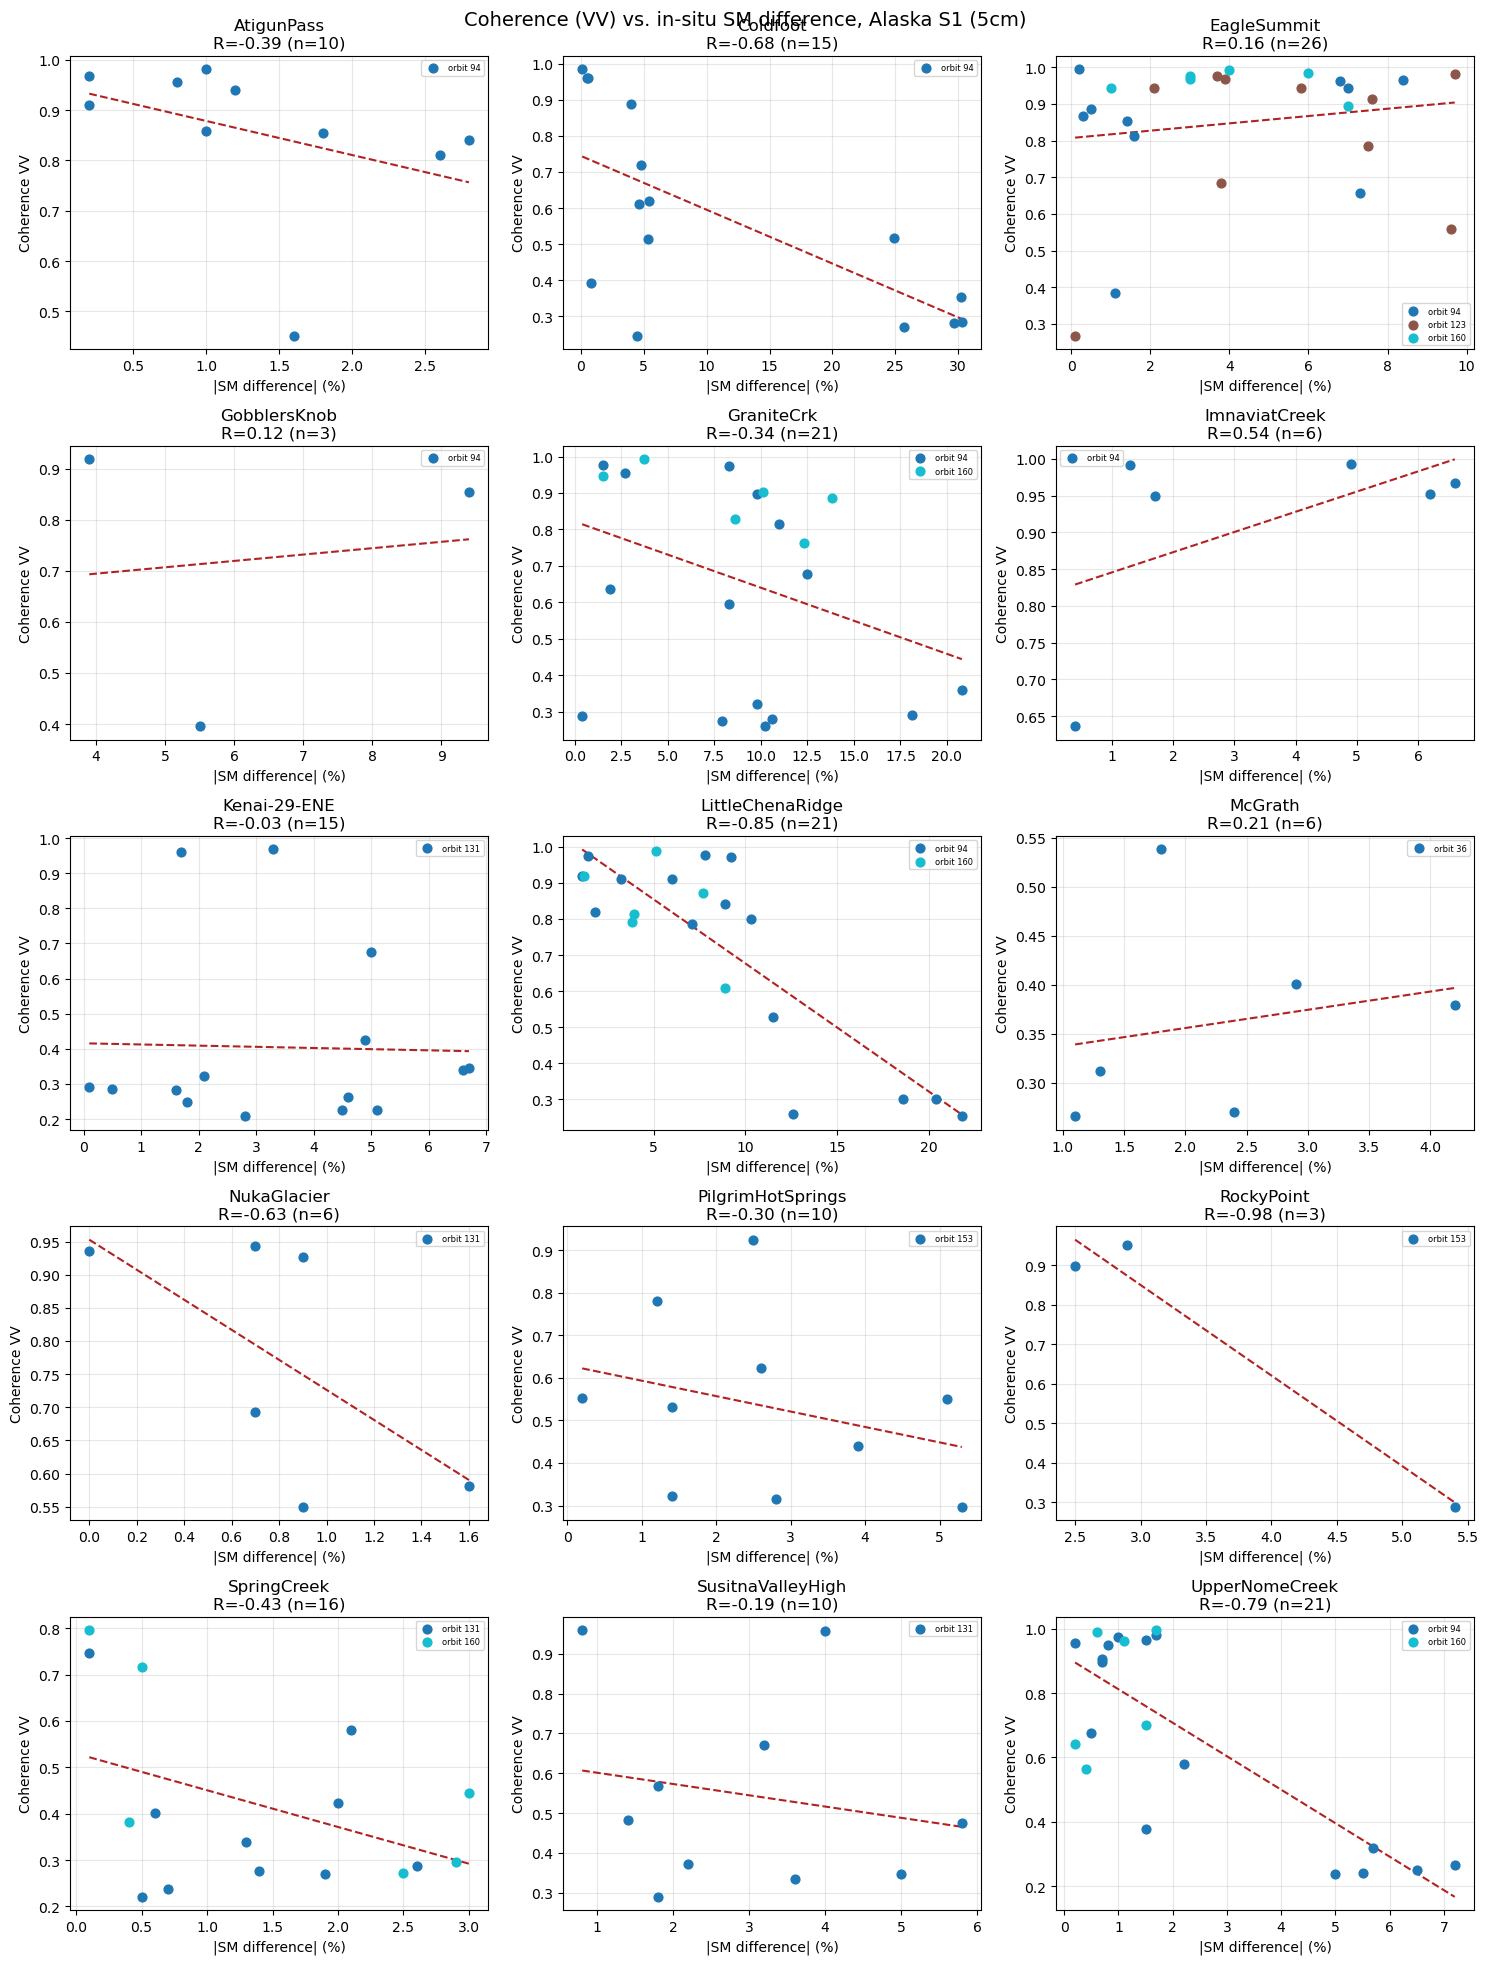

Pearson R (|SM diff| vs coherence_VV) per station, 5cm -- De Zan predicts negative:
  AtigunPass: R=-0.391
  Coldfoot: R=-0.678
  EagleSummit: R=0.162
  GobblersKnob: R=0.124
  GraniteCrk: R=-0.342
  ImnaviatCreek: R=0.540
  Kenai-29-ENE: R=-0.028
  LittleChenaRidge: R=-0.845
  McGrath: R=0.209
  NukaGlacier: R=-0.628
  PilgrimHotSprings: R=-0.299
  RockyPoint: R=-0.980
  SpringCreek: R=-0.427
  SusitnaValleyHigh: R=-0.188
  UpperNomeCreek: R=-0.791


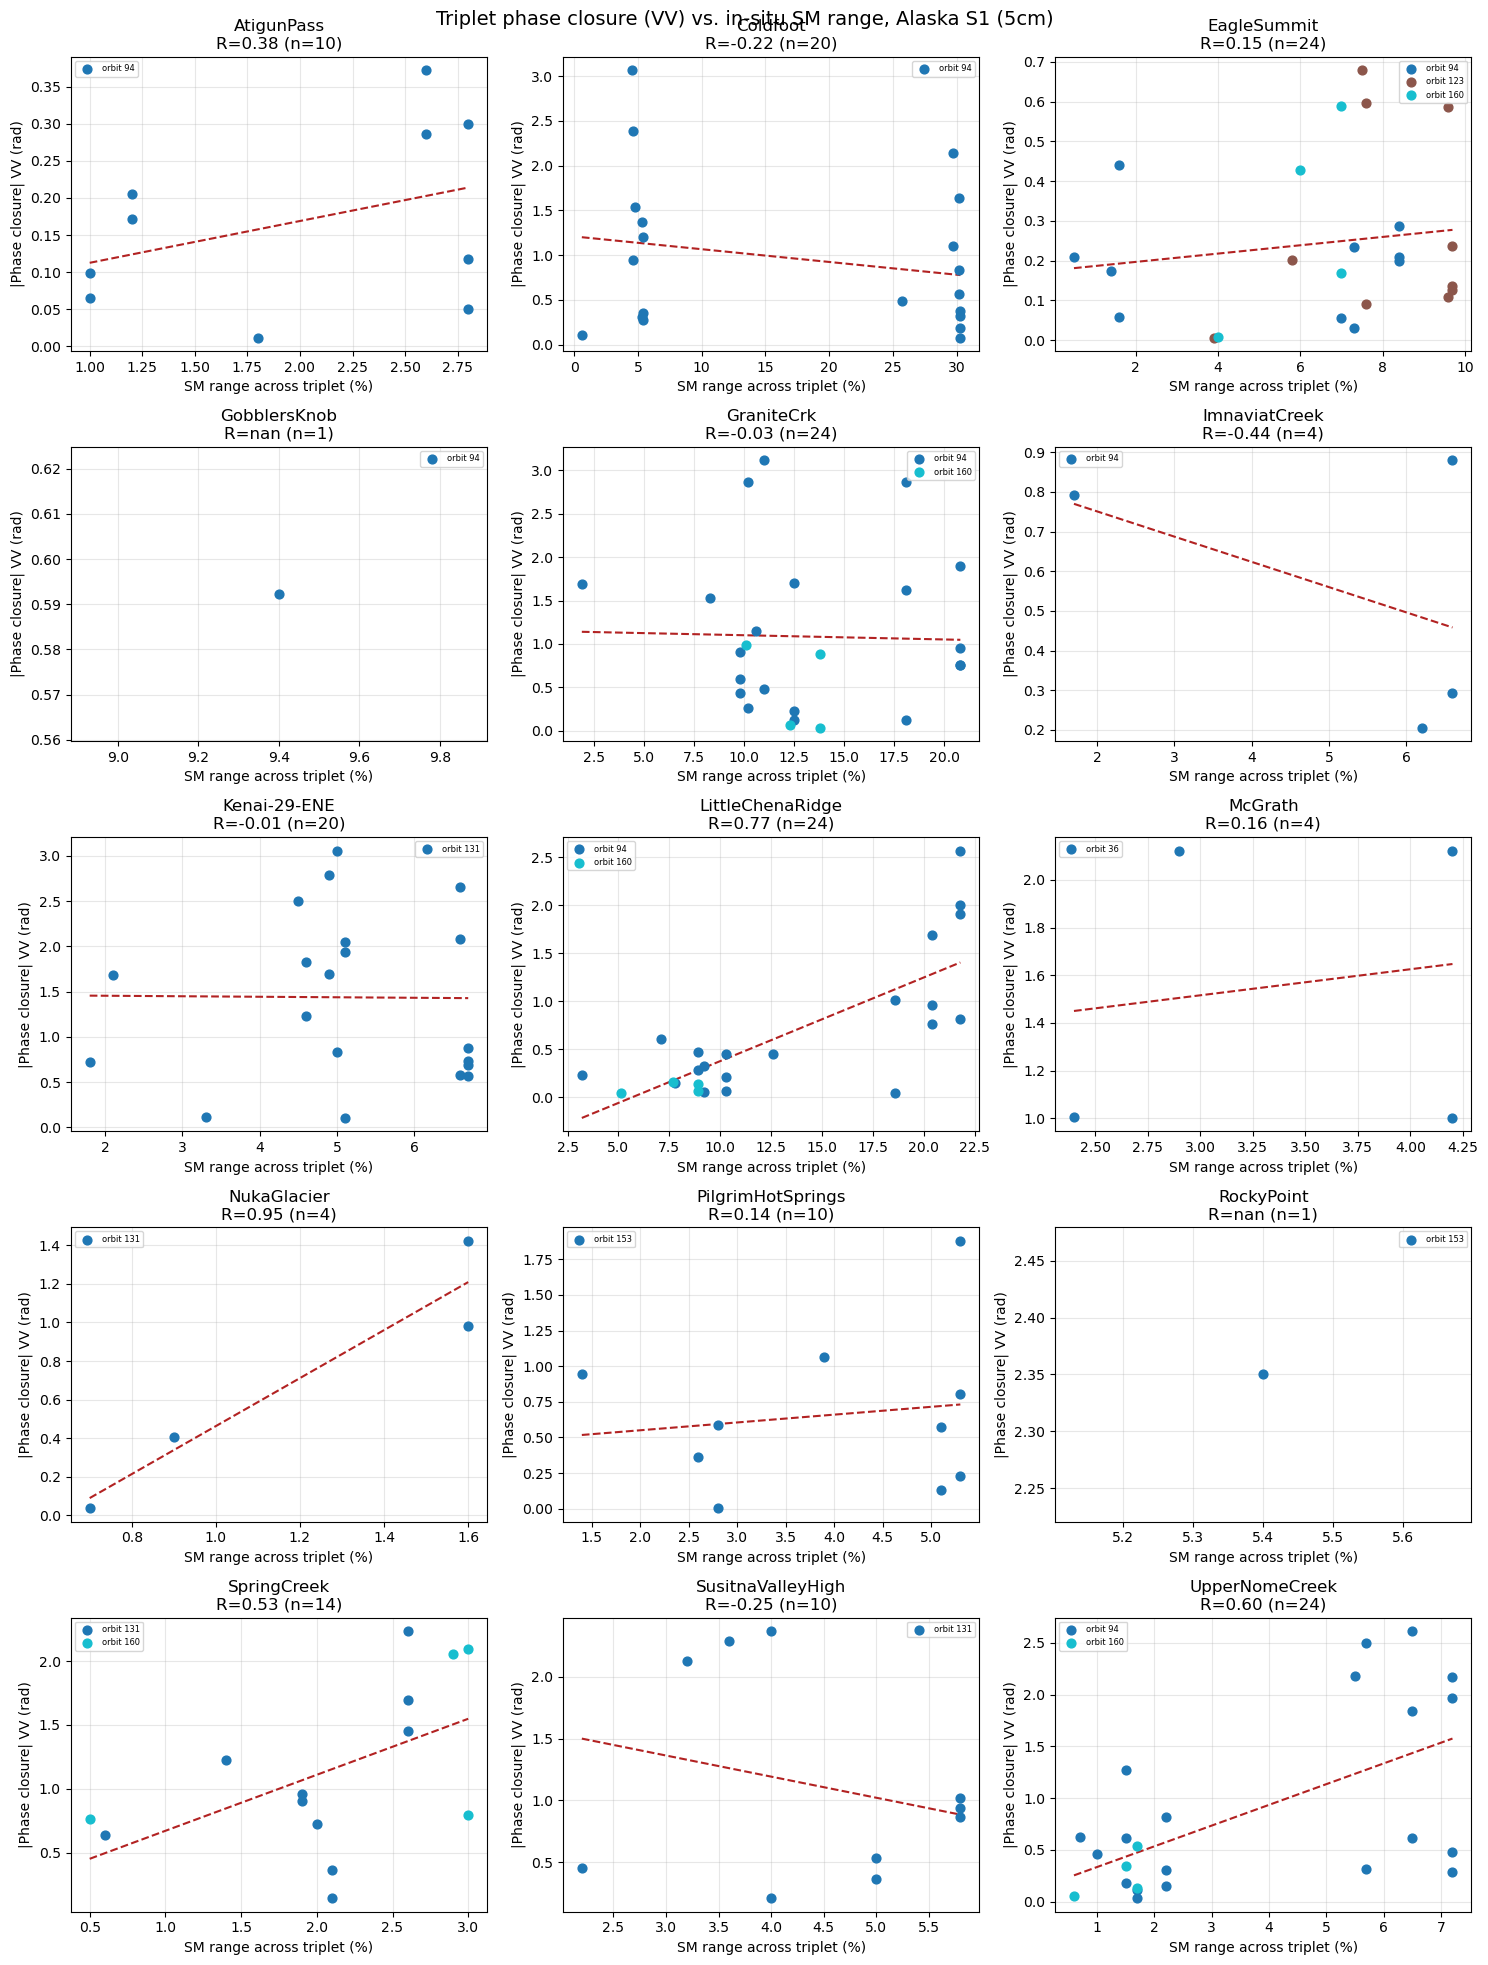

Pearson R (SM range vs |phase closure_VV|) per station, 5cm -- De Zan predicts positive:
  AtigunPass: R=0.381
  Coldfoot: R=-0.220
  EagleSummit: R=0.149
  GobblersKnob: R=nan
  GraniteCrk: R=-0.026
  ImnaviatCreek: R=-0.444
  Kenai-29-ENE: R=-0.009
  LittleChenaRidge: R=0.766
  McGrath: R=0.155
  NukaGlacier: R=0.952
  PilgrimHotSprings: R=0.145
  RockyPoint: R=nan
  SpringCreek: R=0.531
  SusitnaValleyHigh: R=-0.254
  UpperNomeCreek: R=0.603


In [6]:
require_globals("join_and_compare", "plot_coherence_vs_dsm", "plot_closure_vs_range", "DEPTH_MAIN")

coherence_5cm, closure_5cm = join_and_compare(DEPTH_MAIN)
r_coh_5cm = plot_coherence_vs_dsm(coherence_5cm, "5cm")
r_clo_5cm = plot_closure_vs_range(closure_5cm, "5cm")


## 6. 20cm depth (secondary comparison)

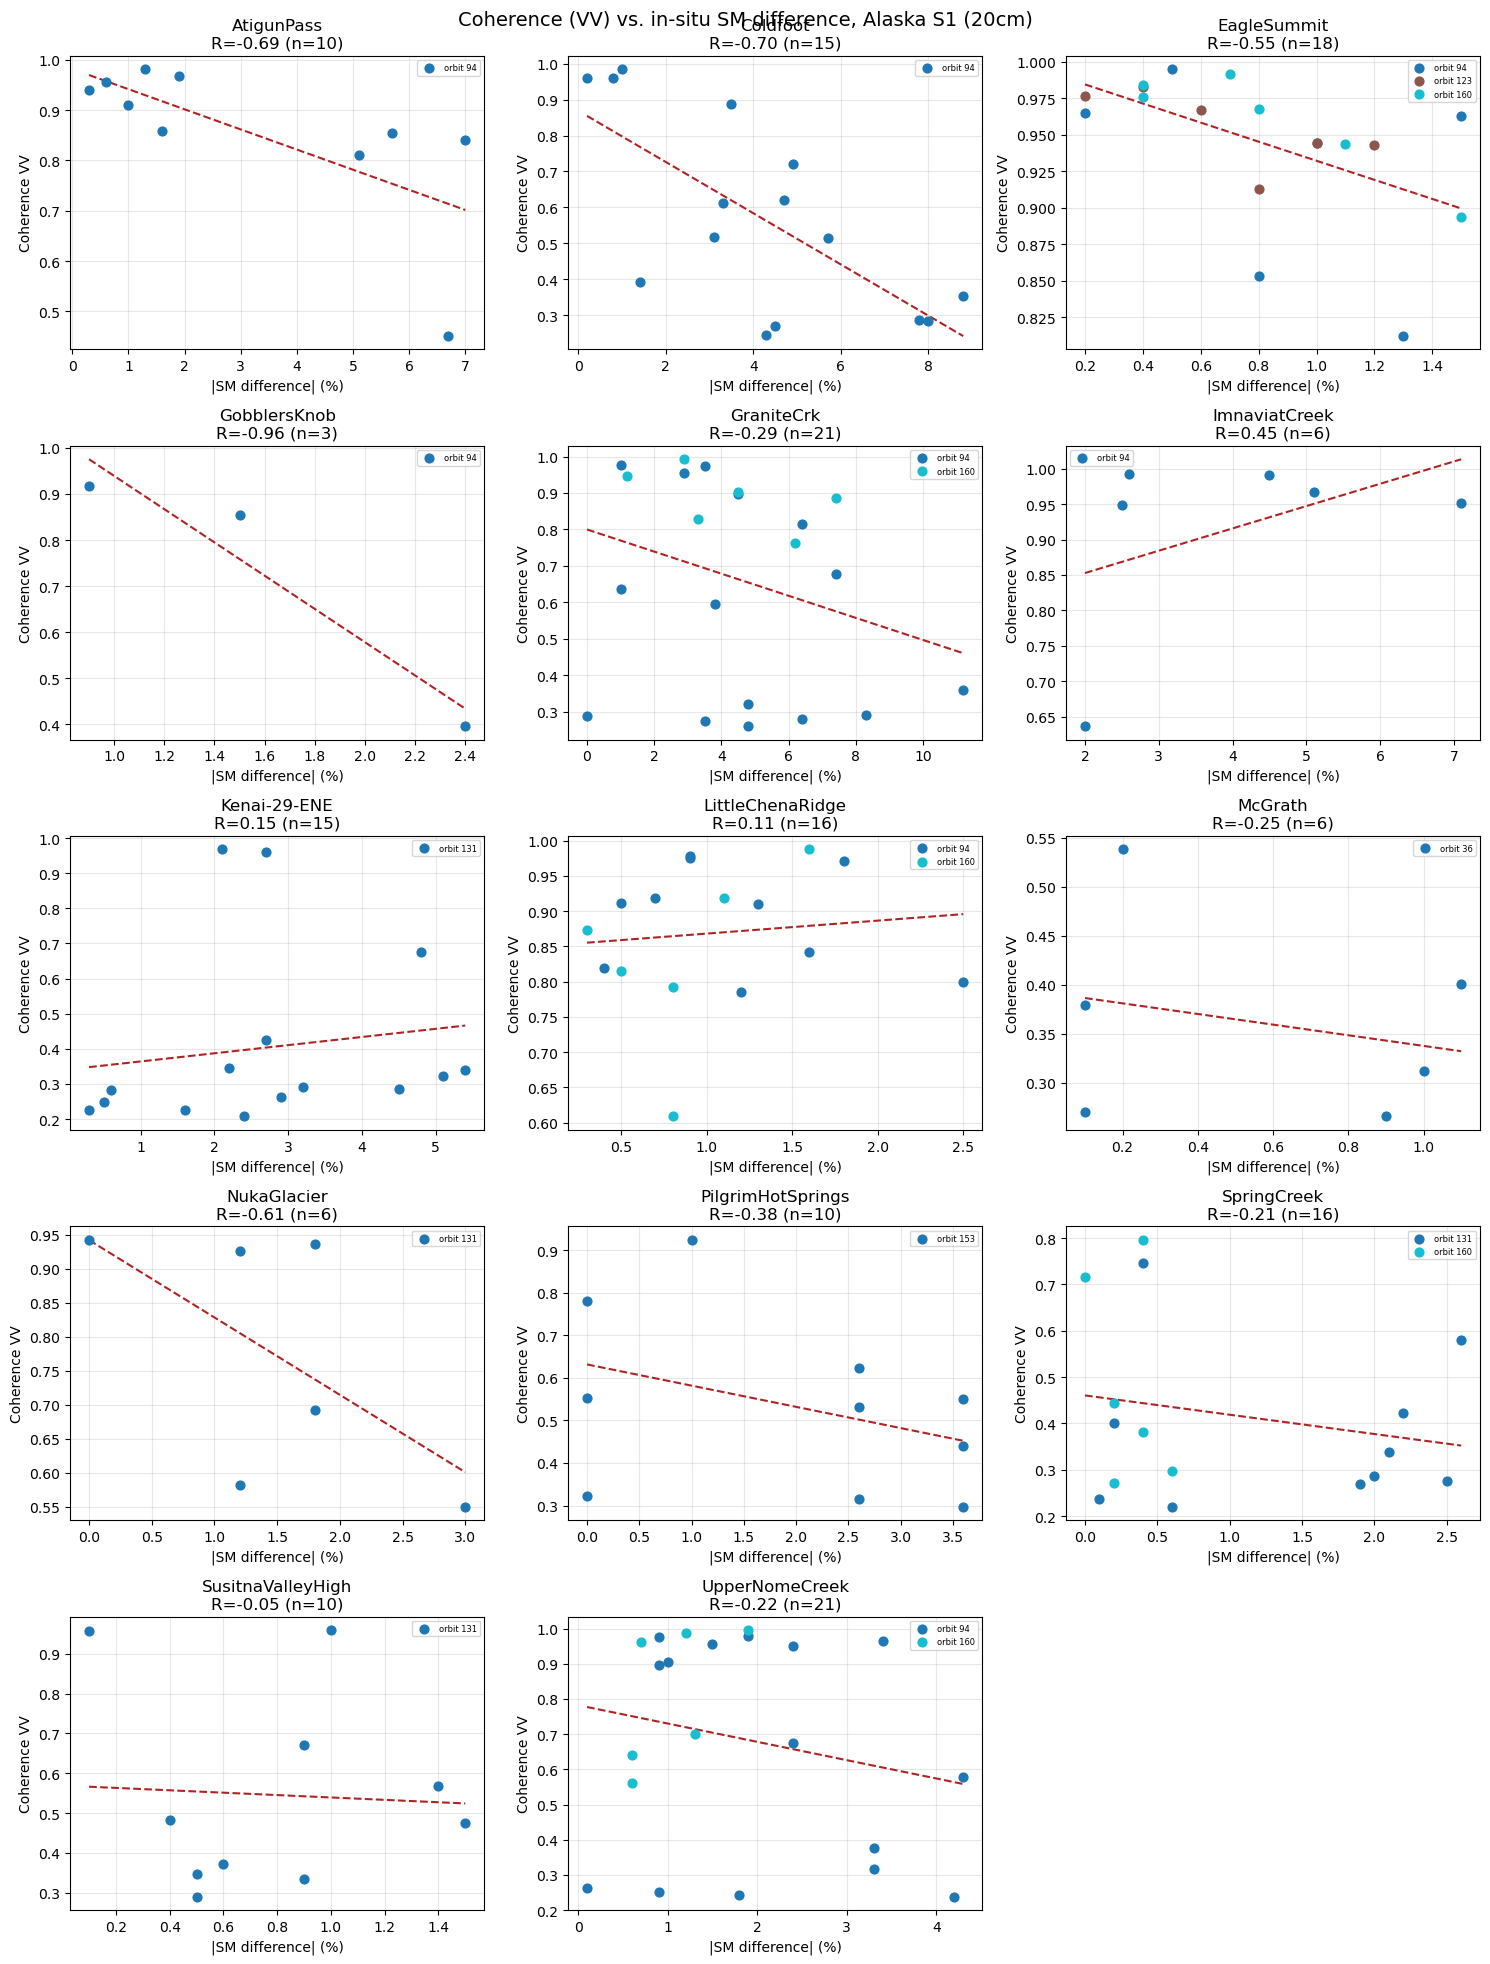

Pearson R (|SM diff| vs coherence_VV) per station, 20cm -- De Zan predicts negative:
  AtigunPass: R=-0.693
  Coldfoot: R=-0.695
  EagleSummit: R=-0.550
  GobblersKnob: R=-0.957
  GraniteCrk: R=-0.291
  ImnaviatCreek: R=0.449
  Kenai-29-ENE: R=0.150
  LittleChenaRidge: R=0.110
  McGrath: R=-0.253
  NukaGlacier: R=-0.606
  PilgrimHotSprings: R=-0.377
  SpringCreek: R=-0.215
  SusitnaValleyHigh: R=-0.054
  UpperNomeCreek: R=-0.216


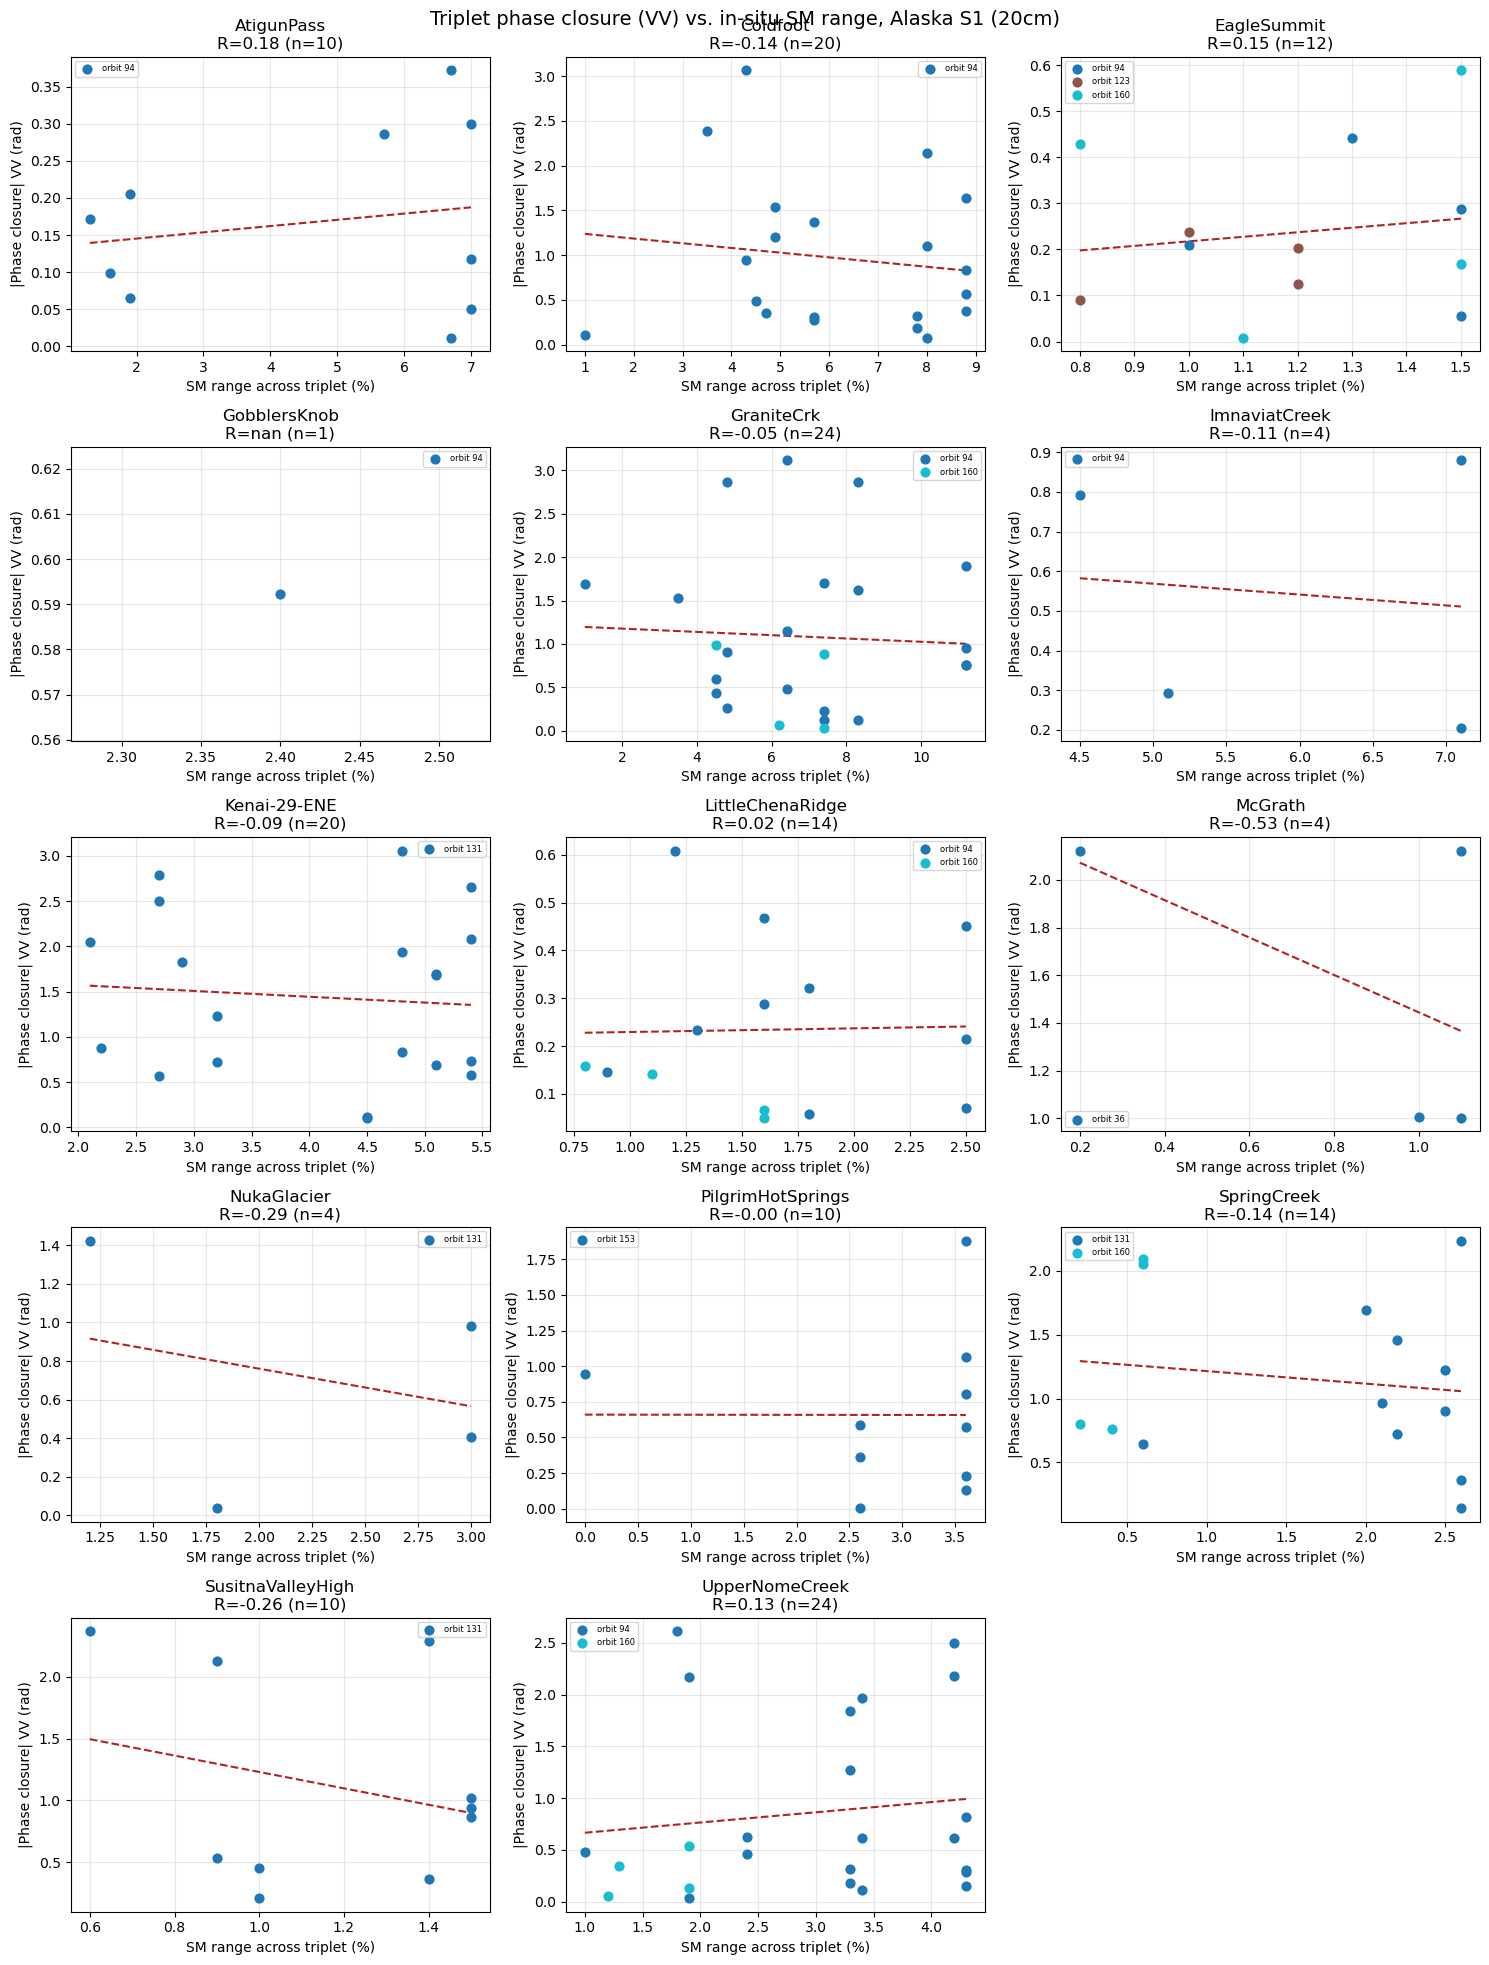

Pearson R (SM range vs |phase closure_VV|) per station, 20cm -- De Zan predicts positive:
  AtigunPass: R=0.183
  Coldfoot: R=-0.138
  EagleSummit: R=0.151
  GobblersKnob: R=nan
  GraniteCrk: R=-0.055
  ImnaviatCreek: R=-0.108
  Kenai-29-ENE: R=-0.086
  LittleChenaRidge: R=0.025
  McGrath: R=-0.529
  NukaGlacier: R=-0.286
  PilgrimHotSprings: R=-0.001
  SpringCreek: R=-0.142
  SusitnaValleyHigh: R=-0.260
  UpperNomeCreek: R=0.130


In [7]:
require_globals("join_and_compare", "plot_coherence_vs_dsm", "plot_closure_vs_range", "DEPTH_SECONDARY")

coherence_20cm, closure_20cm = join_and_compare(DEPTH_SECONDARY)
r_coh_20cm = plot_coherence_vs_dsm(coherence_20cm, "20cm")
r_clo_20cm = plot_closure_vs_range(closure_20cm, "20cm")


## 7. Overall comparison: 5cm vs. 20cm

No polarization axis to pool here (VV only), unlike `Checks_alaska.ipynb`'s
8-combination table -- just the two depths.

=== Coherence vs. |SM difference| (De Zan predicts negative R) ===


,depth,n_stations,mean_R,median_R,n_correct_sign,frac_correct_sign
0,5cm,15,-0.304206,-0.342191,11,0.733333
1,20cm,14,-0.299777,-0.271922,11,0.785714



=== Closure phase vs. SM range (De Zan predicts positive R) ===


,depth,n_stations,mean_R,median_R,n_correct_sign,frac_correct_sign
0,5cm,13,0.209981,0.149013,8,0.615385
1,20cm,13,-0.085827,-0.086061,4,0.307692


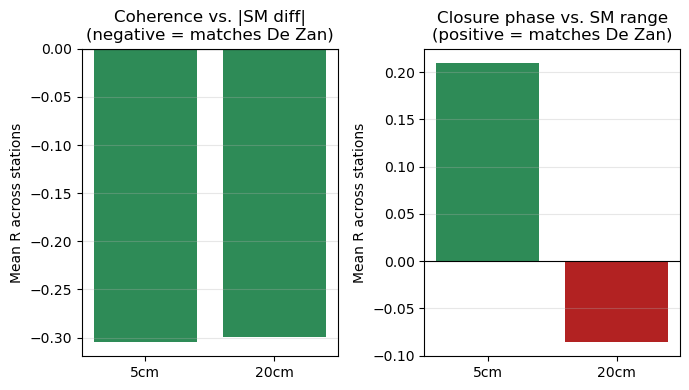

In [8]:
require_globals("r_coh_5cm", "r_coh_20cm", "r_clo_5cm", "r_clo_20cm")

coherence_results = {"5cm": r_coh_5cm, "20cm": r_coh_20cm}
closure_results = {"5cm": r_clo_5cm, "20cm": r_clo_20cm}


def summarize(results_by_depth, expected_sign):
    rows = []
    for depth, r_by_station in results_by_depth.items():
        r_values = np.array([r for r in r_by_station.values() if not np.isnan(r)])
        n_valid = len(r_values)
        n_correct_sign = int(np.sum(r_values * expected_sign > 0))
        rows.append({
            "depth": depth,
            "n_stations": n_valid,
            "mean_R": r_values.mean() if n_valid else np.nan,
            "median_R": np.median(r_values) if n_valid else np.nan,
            "n_correct_sign": n_correct_sign,
            "frac_correct_sign": n_correct_sign / n_valid if n_valid else np.nan,
        })
    df = pd.DataFrame(rows)
    ascending = expected_sign < 0
    return df.sort_values("mean_R", ascending=ascending).reset_index(drop=True)


print("=== Coherence vs. |SM difference| (De Zan predicts negative R) ===")
coherence_summary = summarize(coherence_results, expected_sign=-1)
display(coherence_summary)

print("\n=== Closure phase vs. SM range (De Zan predicts positive R) ===")
closure_summary = summarize(closure_results, expected_sign=+1)
display(closure_summary)

fig, (ax_coh, ax_clo) = plt.subplots(1, 2, figsize=(7, 4))
for ax, summary, title in (
    (ax_coh, coherence_summary, "Coherence vs. |SM diff|\n(negative = matches De Zan)"),
    (ax_clo, closure_summary, "Closure phase vs. SM range\n(positive = matches De Zan)"),
):
    colors = ["seagreen" if c else "firebrick" for c in summary["n_correct_sign"] >= summary["n_stations"] / 2]
    ax.bar(summary["depth"], summary["mean_R"], color=colors)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("Mean R across stations")
    ax.set_title(title)
    ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 8. NDVI vs. coherence

Same check as `Checks_alaska.ipynb`'s own Section 9: vegetation canopy change
between two acquisitions is a well known secondary source of InSAR temporal
decorrelation, independent of the De Zan soil-moisture mechanism above. Reads
`alaska_HLS_ndvi/{station}_HLS_ndvi.csv`
([`05_get_HLS_ndvi.ipynb`](Earsel26_NISAR-main/notebooks/05_get_HLS_ndvi.ipynb)),
computes `dndvi = |NDVI(date_1) - NDVI(date_2)|` per coherence pair and
correlates it against `coherence_VV` -- De Zan-independent prediction:
more vegetation change should mean more decorrelation, i.e. a **negative** R.

**Different join from the NISAR notebook**: that NDVI data was sampled at each
station's *NISAR* acquisition dates (`target_date` there comes straight from
NISAR's own acquisition list), not Sentinel-1's -- S1 and NISAR pass over a
station on different calendar days, so `date_1`/`date_2` here essentially never
match a `target_date` exactly. NDVI changes slowly (vegetation phenology, not
soil moisture), so `read_ndvi` here does a **nearest-date match within
`MAX_NDVI_GAP_DAYS`** instead of an exact one -- the same "bracket with a cap"
principle `interp_insitu_at` and `S1_burst_stations.ipynb`'s own NISAR/S1 date
matching already use elsewhere in this project, not a new convention.

In [9]:
require_globals("coherence_by_station", "MIN_BASELINE_DAYS", "EARSEL_NOTEBOOKS")

NDVI_DIR = EARSEL_NOTEBOOKS / "nisar_data" / "alaska_HLS_ndvi"
MAX_NDVI_GAP_DAYS = 5  # NDVI is sampled at NISAR dates, not S1 dates -- nearest reading within this many days stands in


def read_ndvi(station):
    path = NDVI_DIR / f"{station}_HLS_ndvi.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, parse_dates=["target_date"])
    df = df[df["n_valid_px"] > 0]
    if df.empty:
        return None
    return df.set_index("target_date")["ndvi_mean"].sort_index()


def nearest_ndvi_at(ndvi_series, ts, max_gap_days=MAX_NDVI_GAP_DAYS):
    if ndvi_series is None or ndvi_series.empty:
        return np.nan
    idx = ndvi_series.index
    pos = idx.get_indexer([ts], method="nearest")[0]
    if pos == -1:
        return np.nan
    if abs((idx[pos] - ts).total_seconds()) > max_gap_days * 86400:
        return np.nan
    return float(ndvi_series.iloc[pos])


ndvi_dfs = {}
for station, df_coh in coherence_by_station.items():
    ndvi_series = read_ndvi(station)
    if ndvi_series is None:
        continue
    df = df_coh[df_coh["temporal_baseline_days"] >= MIN_BASELINE_DAYS].copy()
    df["ndvi_1"] = df["date_1"].apply(lambda ts: nearest_ndvi_at(ndvi_series, ts))
    df["ndvi_2"] = df["date_2"].apply(lambda ts: nearest_ndvi_at(ndvi_series, ts))
    df["dndvi"] = (df["ndvi_1"] - df["ndvi_2"]).abs()
    ndvi_dfs[station] = df

print(f"{len(ndvi_dfs)}/{len(coherence_by_station)} station(s) have usable NDVI data")
for station, df in ndvi_dfs.items():
    n_usable = df["dndvi"].notna().sum()
    print(f"  {station}: {n_usable}/{len(df)} pair(s) with both dates' NDVI available "
          f"(within {MAX_NDVI_GAP_DAYS} days)")


15/16 station(s) have usable NDVI data
  Coldfoot: 3/15 pair(s) with both dates' NDVI available (within 5 days)
  EagleSummit: 1/36 pair(s) with both dates' NDVI available (within 5 days)
  GobblersKnob: 1/15 pair(s) with both dates' NDVI available (within 5 days)
  GraniteCrk: 6/21 pair(s) with both dates' NDVI available (within 5 days)
  ImnaviatCreek: 0/15 pair(s) with both dates' NDVI available (within 5 days)
  Kenai-29-ENE: 6/15 pair(s) with both dates' NDVI available (within 5 days)
  LittleChenaRidge: 4/21 pair(s) with both dates' NDVI available (within 5 days)
  McGrath: 0/6 pair(s) with both dates' NDVI available (within 5 days)
  NukaGlacier: 6/6 pair(s) with both dates' NDVI available (within 5 days)
  PilgrimHotSprings: 0/10 pair(s) with both dates' NDVI available (within 5 days)
  RockyPoint: 1/10 pair(s) with both dates' NDVI available (within 5 days)
  SpringCreek: 7/16 pair(s) with both dates' NDVI available (within 5 days)
  SusitnaValleyHigh: 0/10 pair(s) with both d

C:\Users\geoka\AppData\Local\Temp\ipykernel_14696\3182119554.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=6, loc="best")


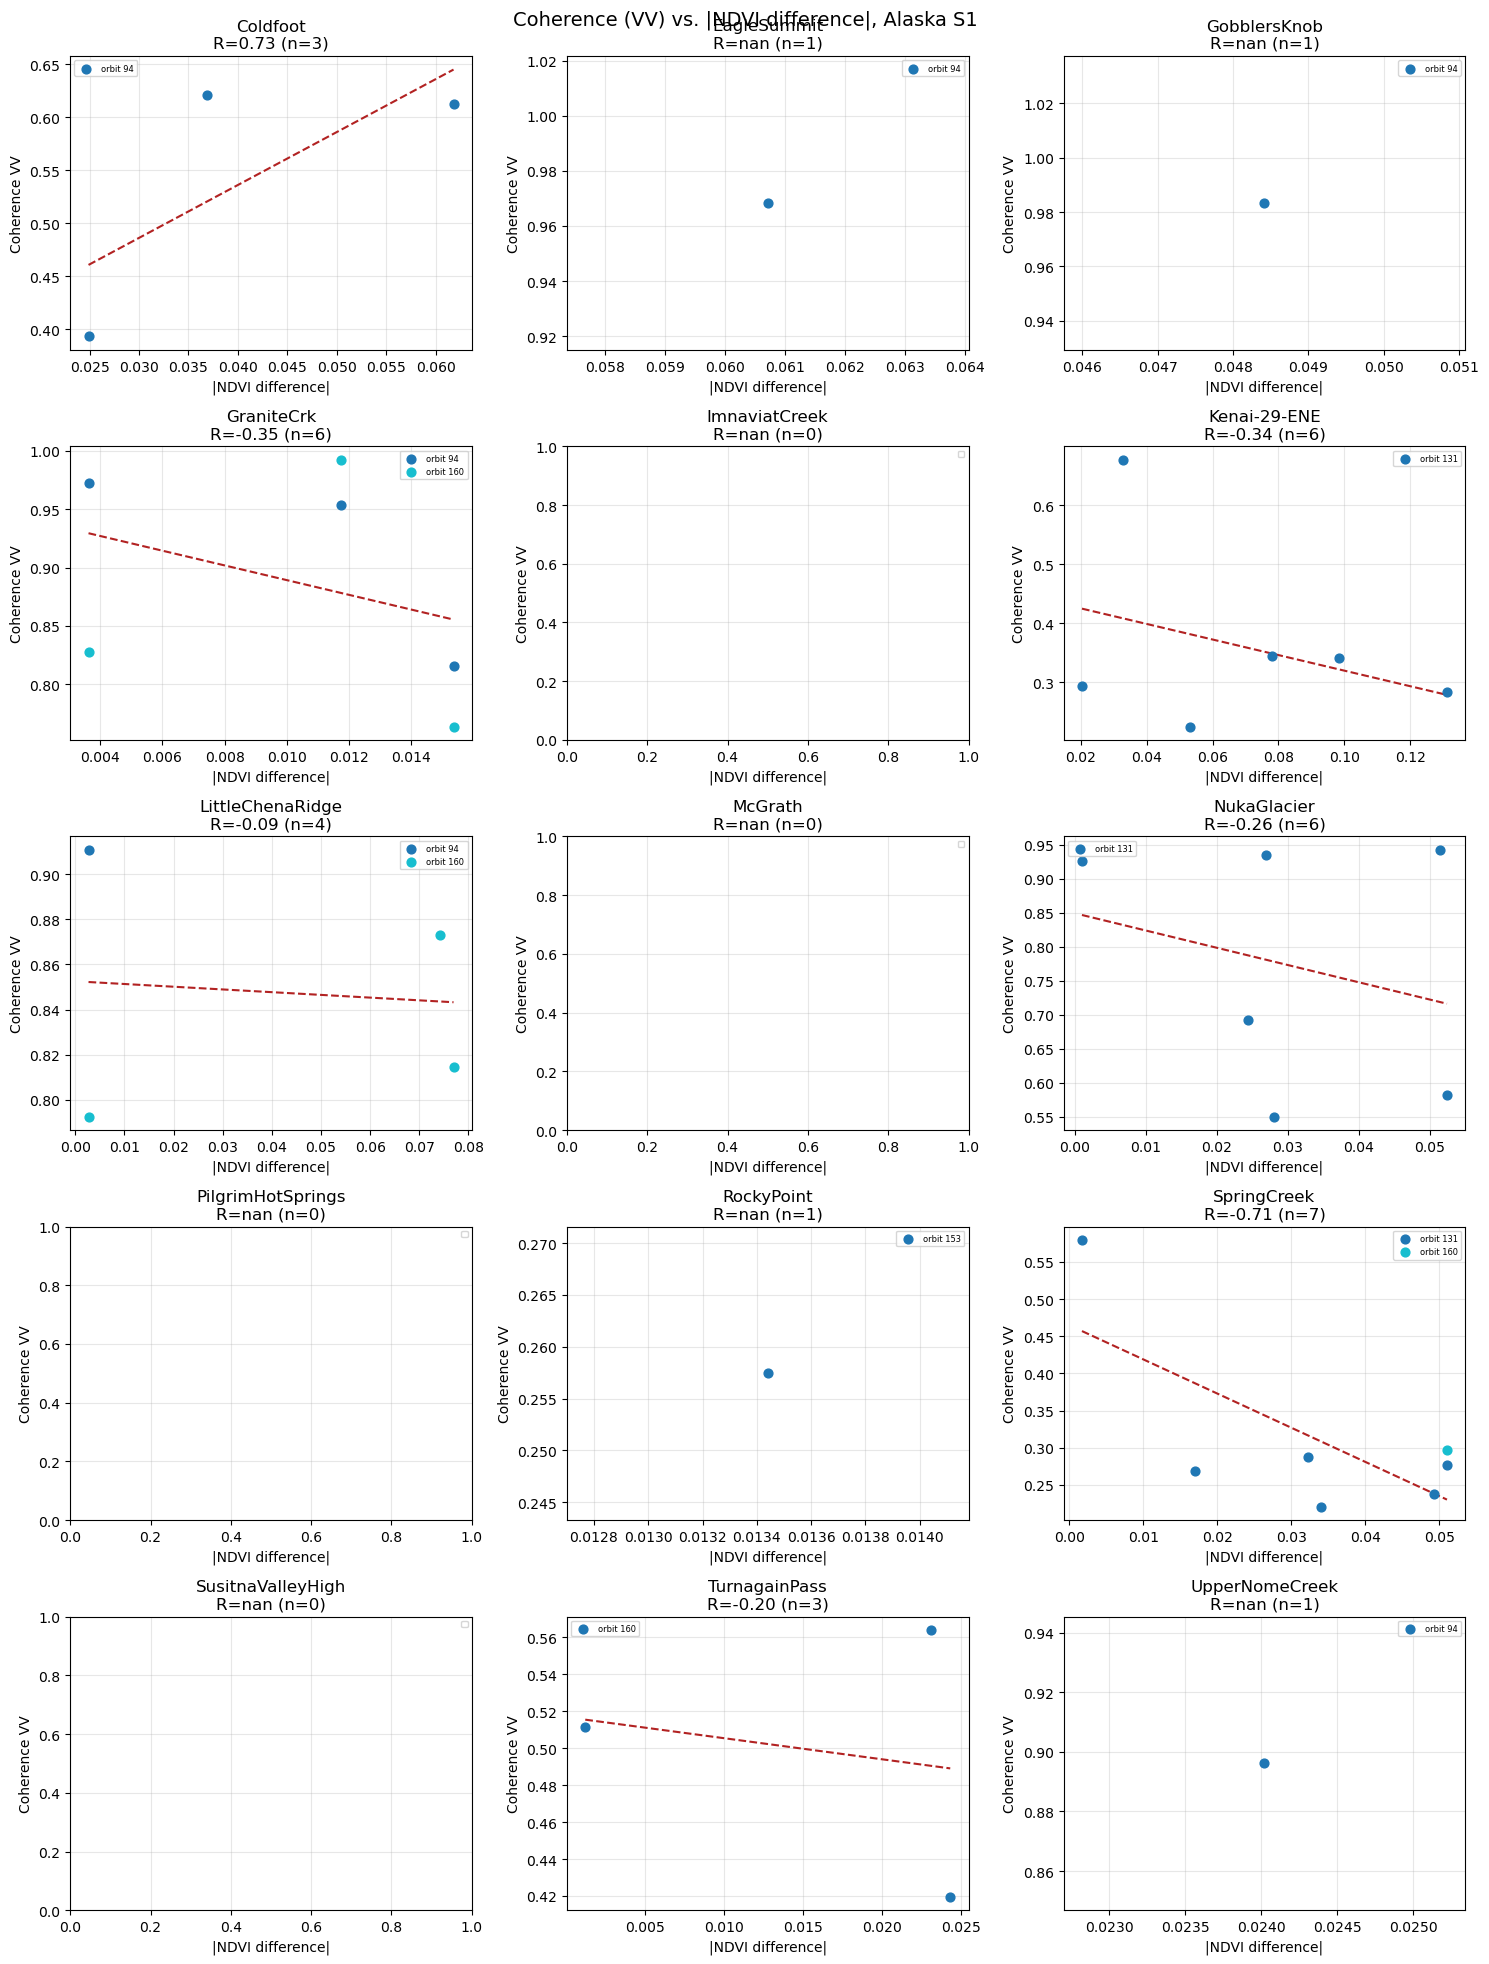

Pearson R (|NDVI diff| vs coherence_VV) per station -- more vegetation change should mean more decorrelation, predicts negative:
  Coldfoot: R=0.728
  EagleSummit: R=nan
  GobblersKnob: R=nan
  GraniteCrk: R=-0.351
  ImnaviatCreek: R=nan
  Kenai-29-ENE: R=-0.343
  LittleChenaRidge: R=-0.094
  McGrath: R=nan
  NukaGlacier: R=-0.263
  PilgrimHotSprings: R=nan
  RockyPoint: R=nan
  SpringCreek: R=-0.712
  SusitnaValleyHigh: R=nan
  TurnagainPass: R=-0.203
  UpperNomeCreek: R=nan


In [10]:
require_globals("ndvi_dfs")


def plot_coherence_vs_dndvi(ndvi_dfs):
    station_list = list(ndvi_dfs.keys())
    n_stations = len(station_list)
    ncols = 3
    nrows = int((n_stations + ncols - 1) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4))
    axes = axes.flatten()

    r_by_station = {}
    for idx, station in enumerate(station_list):
        ax = axes[idx]
        df_v = ndvi_dfs[station]
        valid = df_v["coherence_VV"].notna() & df_v["dndvi"].notna()
        df_v = df_v.loc[valid]
        x = df_v["dndvi"].values
        y = df_v["coherence_VV"].values
        r = np.corrcoef(x, y)[0, 1] if len(x) > 1 else np.nan
        r_by_station[station] = r

        orbits = sorted(df_v["orbit"].unique())
        colors = cm.tab10(np.linspace(0, 1, max(len(orbits), 1)))
        for orbit, color in zip(orbits, colors):
            m = df_v["orbit"] == orbit
            ax.scatter(df_v.loc[m, "dndvi"], df_v.loc[m, "coherence_VV"], color=color, s=40,
                       label=f"orbit {orbit}", zorder=3)
        if len(x) > 1:
            fit = np.polyfit(x, y, 1)
            xs = np.linspace(x.min(), x.max(), 10)
            ax.plot(xs, np.polyval(fit, xs), "--", color="firebrick", linewidth=1.5)
        ax.set_title(f"{station}\nR={r:.2f} (n={len(x)})")
        ax.set_xlabel("|NDVI difference|")
        ax.set_ylabel("Coherence VV")
        ax.legend(fontsize=6, loc="best")
        ax.grid(True, alpha=0.3)

    for idx in range(n_stations, len(axes)):
        axes[idx].axis("off")

    plt.suptitle("Coherence (VV) vs. |NDVI difference|, Alaska S1", fontsize=14)
    plt.tight_layout()
    plt.show()

    print("Pearson R (|NDVI diff| vs coherence_VV) per station -- "
          "more vegetation change should mean more decorrelation, predicts negative:")
    for station, r in r_by_station.items():
        print(f"  {station}: R={r:.3f}")
    return r_by_station


r_ndvi = plot_coherence_vs_dndvi(ndvi_dfs)


In [11]:
require_globals("ndvi_dfs", "r_ndvi")

rows = []
for station, df in ndvi_dfs.items():
    ndvi_vals = pd.concat([df["ndvi_1"], df["ndvi_2"]]).dropna()
    valid = df["coherence_VV"].notna() & df["dndvi"].notna()
    dv = df.loc[valid]
    rows.append({
        "station": station,
        "n_pairs_total": len(df),
        "n_pairs_usable": len(dv),
        "mean_ndvi": ndvi_vals.mean() if len(ndvi_vals) else np.nan,
        "mean_dndvi": dv["dndvi"].mean() if len(dv) else np.nan,
        "mean_coherence": dv["coherence_VV"].mean() if len(dv) else np.nan,
        "r_ndvi_coherence": r_ndvi.get(station, np.nan),
    })

ndvi_coherence_stats = pd.DataFrame(rows).sort_values("r_ndvi_coherence")
print(ndvi_coherence_stats.to_string(index=False))


          station  n_pairs_total  n_pairs_usable  mean_ndvi  mean_dndvi  mean_coherence  r_ndvi_coherence
      SpringCreek             16               7   0.784969    0.033776        0.309535         -0.712451
       GraniteCrk             21               6   0.779162    0.010243        0.887732         -0.350827
     Kenai-29-ENE             15               6   0.751771    0.068960        0.360489         -0.342506
      NukaGlacier              6               6   0.810276    0.030708        0.771485         -0.263224
    TurnagainPass              6               3   0.864211    0.016216        0.498315         -0.202869
 LittleChenaRidge             21               4   0.828588    0.039160        0.847828         -0.094001
         Coldfoot             15               3   0.806874    0.041202        0.542180          0.728218
      EagleSummit             36               1   0.537081    0.060714        0.968325               NaN
     GobblersKnob             15              

## 9. Per-station overview: coherence, in-situ SM, and NDVI

Same as `Checks_alaska.ipynb`'s own Section 10: one subplot per station with
**coherence** (points, at each pair's midpoint date), **in-situ SM** (a
continuous line), and **NDVI** (a line through `read_ndvi`'s valid readings,
here the nearest-matched values from Section 8) on the same timeline. Three
separate y-axes (coherence left, SM right, NDVI further right, offset), each
using **the same fixed range on every station's subplot** so stations are
directly comparable rather than each subplot autoscaling itself:
- Coherence: `[0, 1]`, its natural bound.
- In-situ SM: `[0, 60]` (%).
- NDVI: `[0.4, 1.0]`.

VV only, so no polarization argument here, unlike the NISAR notebook's HH/HV
split -- called once below for 5cm and once for 20cm.

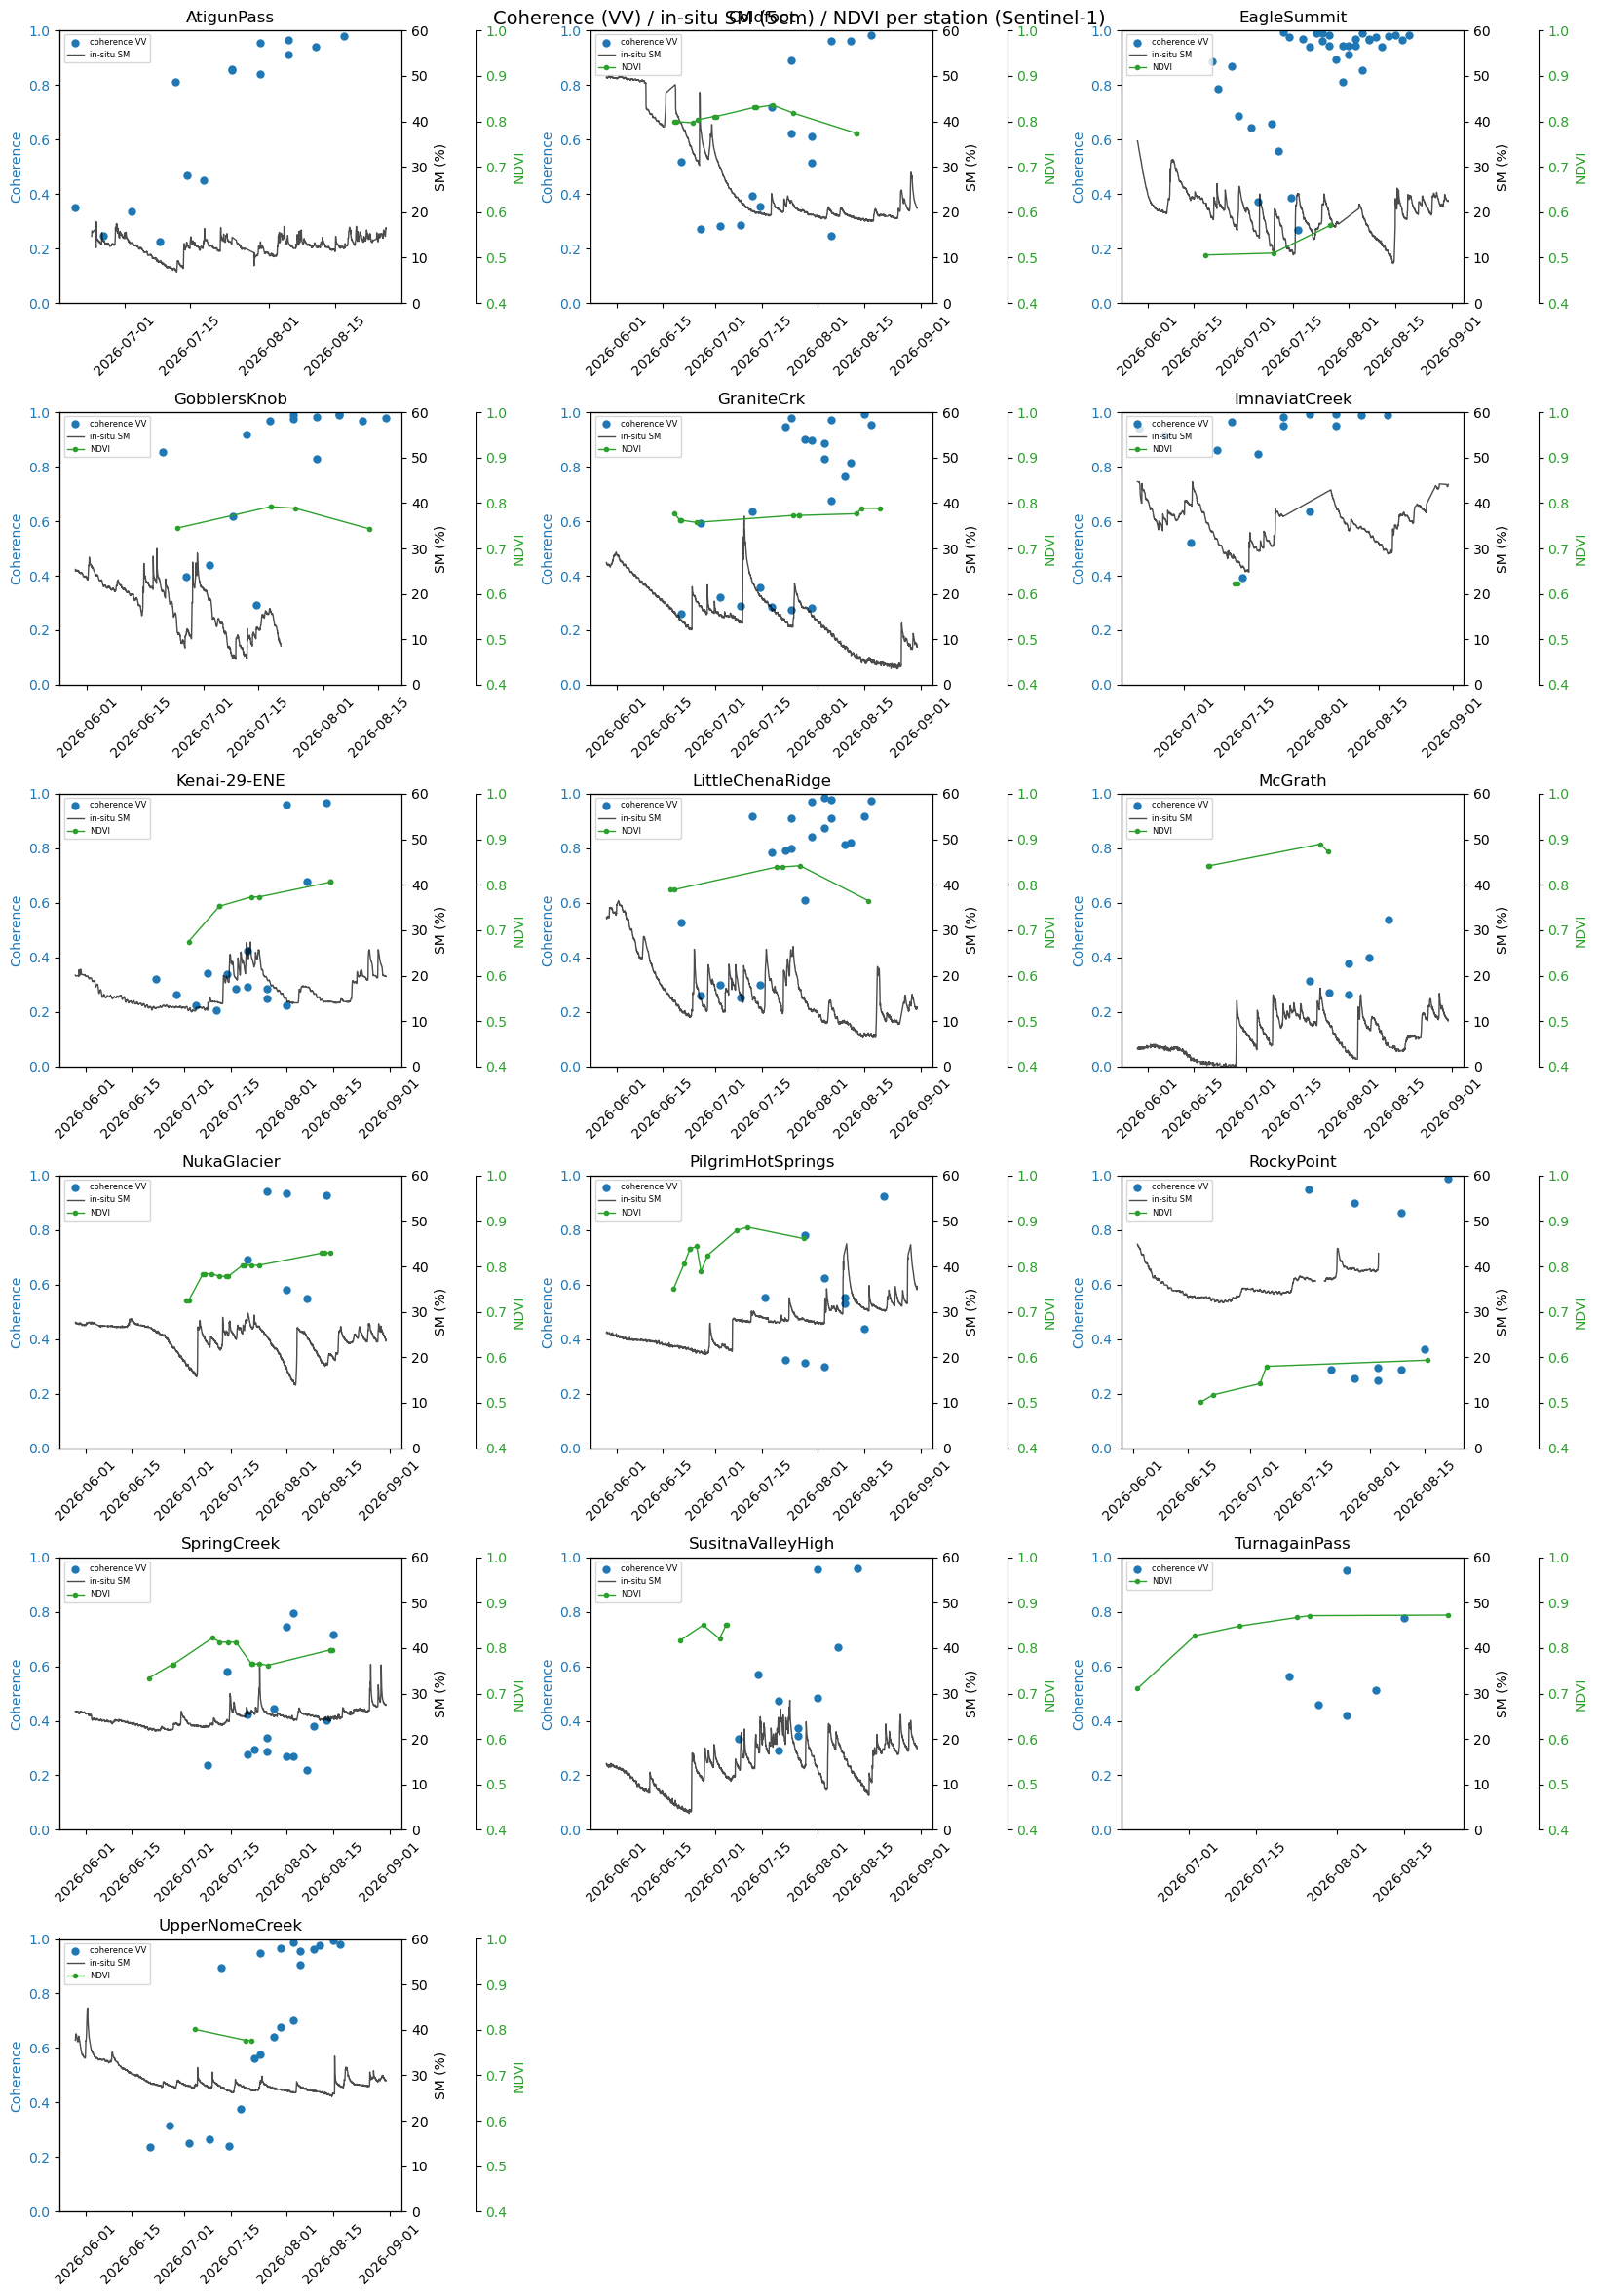

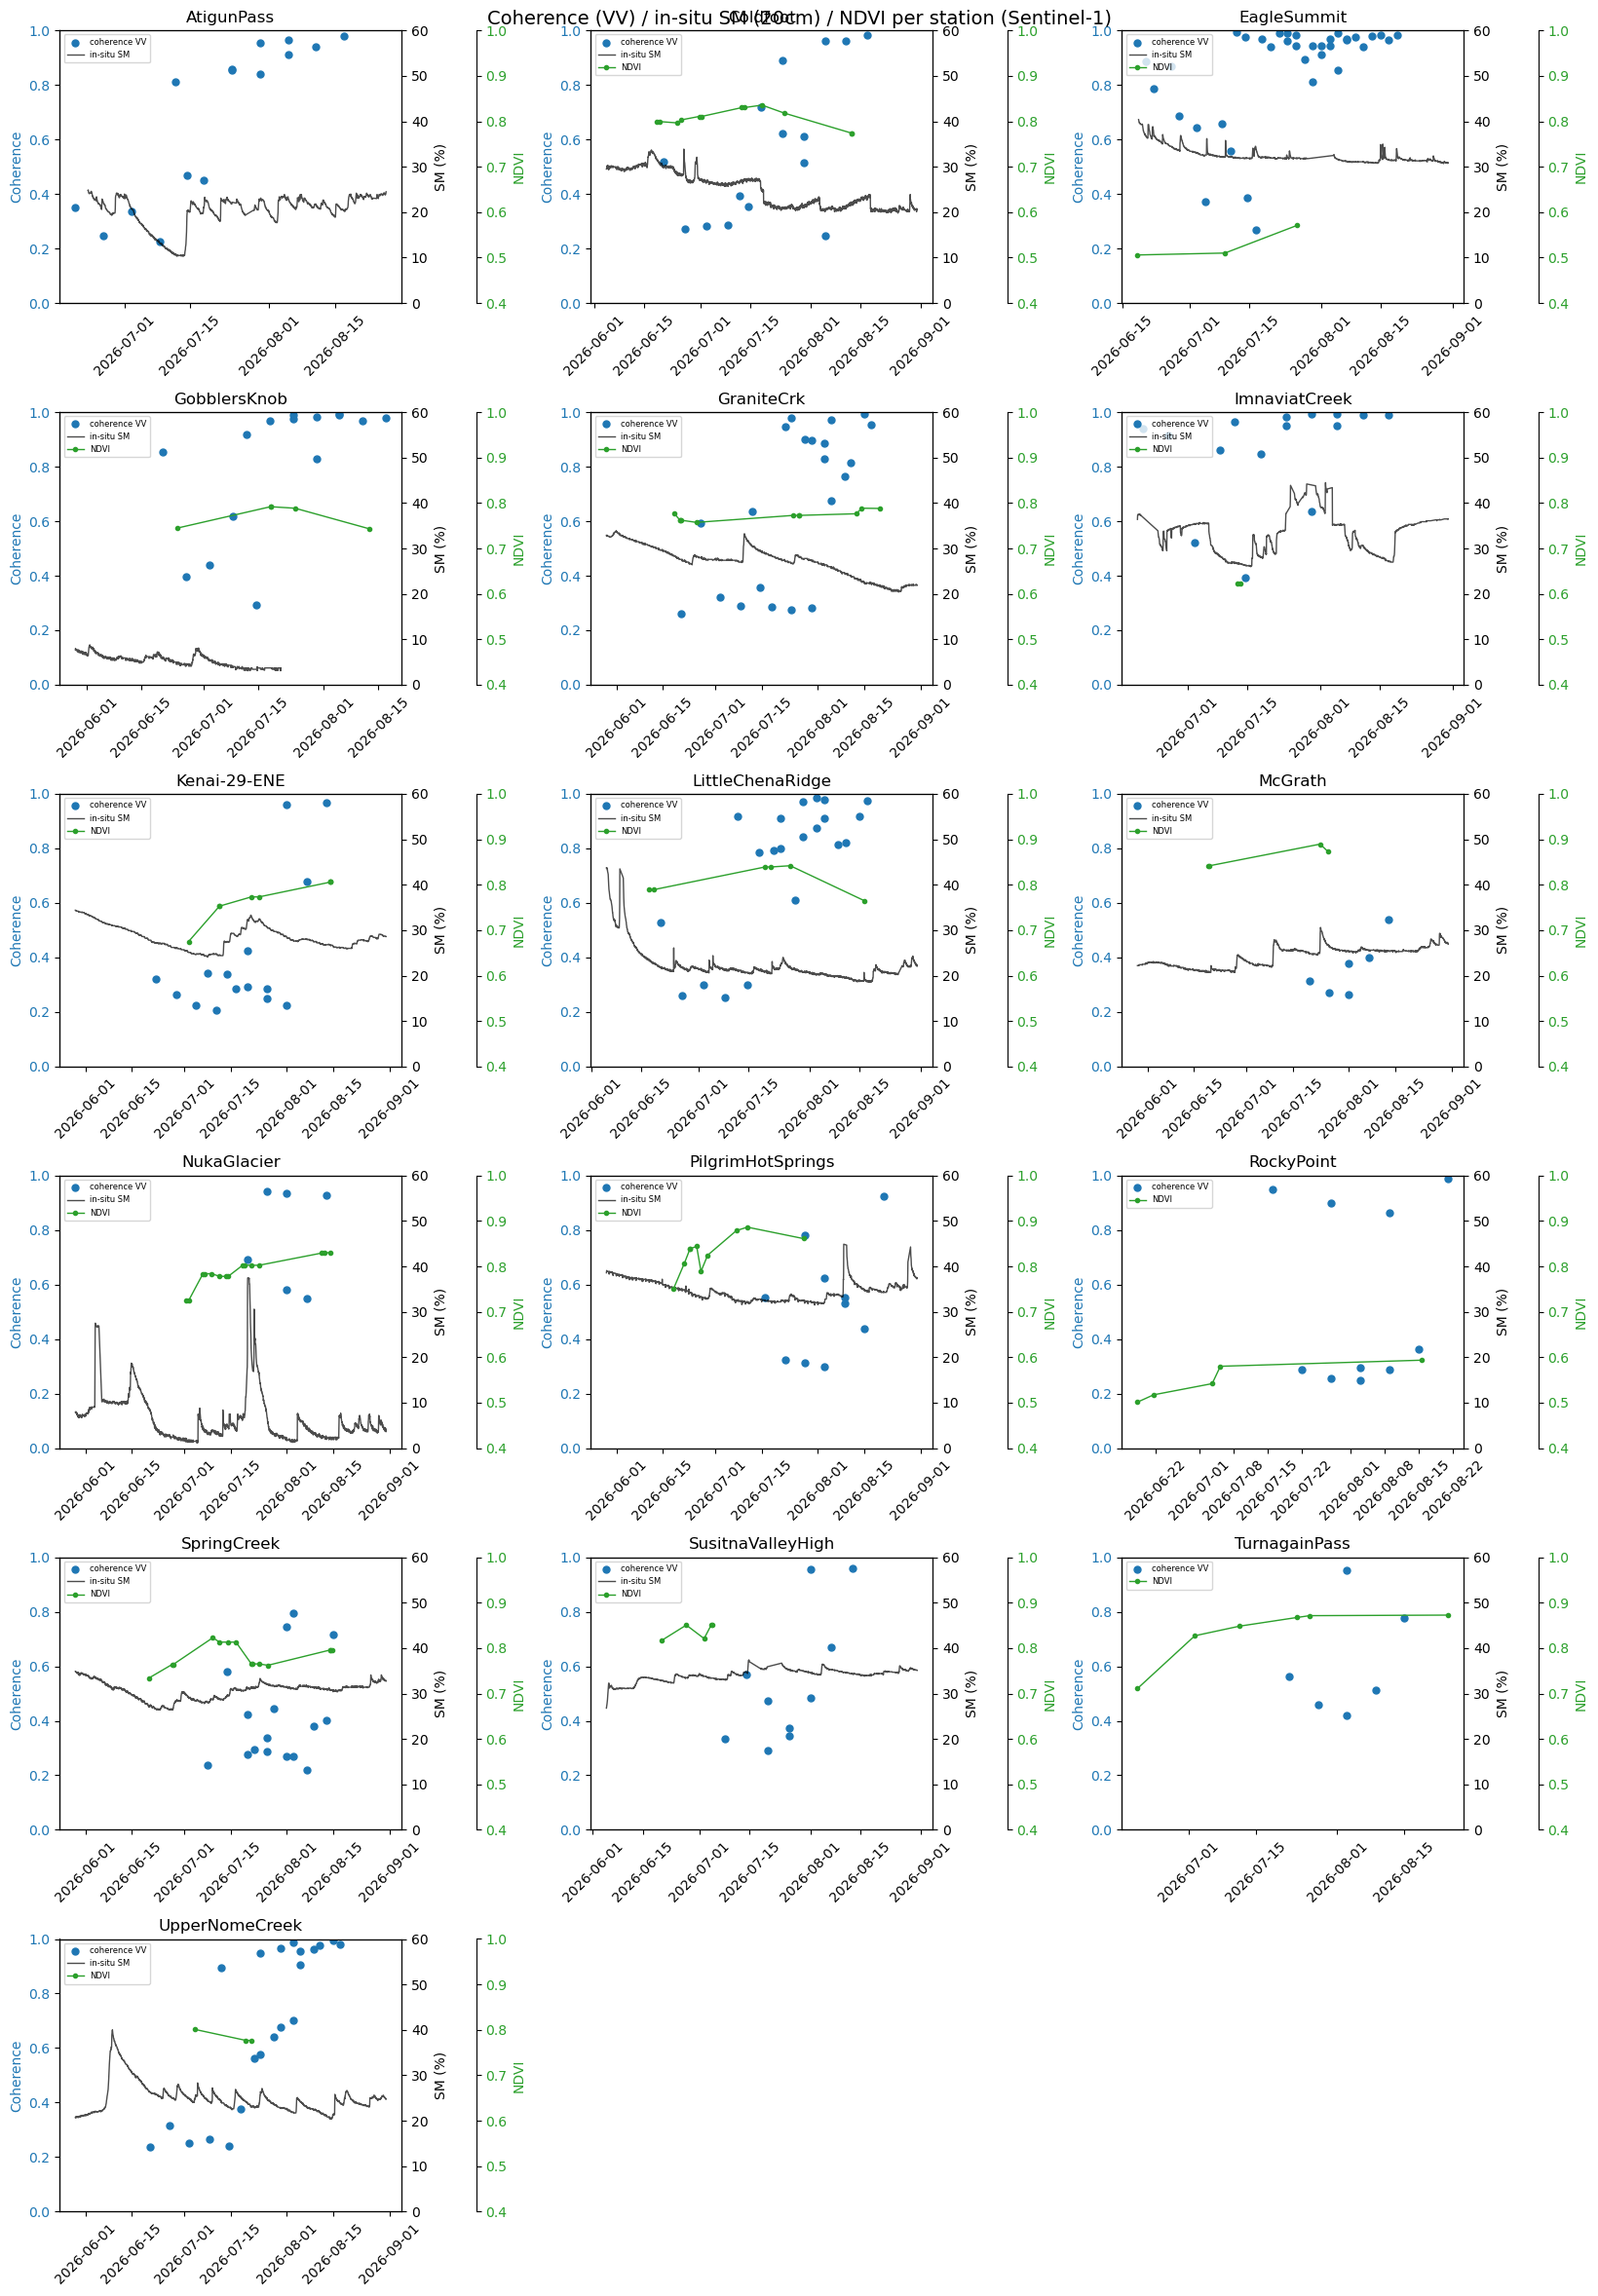

In [12]:
require_globals("coherence_by_station", "MIN_BASELINE_DAYS", "read_insitu", "read_ndvi")

COH_YLIM = (0, 1)
SM_YLIM = (0, 60)
NDVI_YLIM = (0.4, 1.0)


def plot_station_overview(depth):
    depth_label = "5cm" if depth == DEPTH_MAIN else "20cm"
    station_list = sorted(coherence_by_station.keys())
    ncols = 3
    nrows = int((len(station_list) + ncols - 1) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5.5, nrows * 4), squeeze=False)
    axes = axes.flatten()

    for idx, station in enumerate(station_list):
        ax1 = axes[idx]
        ax2 = ax1.twinx()
        ax3 = ax1.twinx()
        ax3.spines["right"].set_position(("outward", 55))

        df_coh = coherence_by_station[station]
        df_coh = df_coh[df_coh["temporal_baseline_days"] >= MIN_BASELINE_DAYS]
        valid_coh = df_coh["coherence_VV"].notna()
        mid_dates = df_coh.loc[valid_coh, "date_1"] + (df_coh.loc[valid_coh, "date_2"] - df_coh.loc[valid_coh, "date_1"]) / 2
        ax1.scatter(mid_dates, df_coh.loc[valid_coh, "coherence_VV"], color="tab:blue", s=25, zorder=3, label="coherence VV")
        ax1.set_ylim(*COH_YLIM)
        ax1.set_ylabel("Coherence", color="tab:blue")
        ax1.tick_params(axis="y", labelcolor="tab:blue")

        sm_series = read_insitu(station, depth)
        if sm_series is not None:
            ax2.plot(sm_series.index, sm_series.values * 100, color="black", linewidth=1, alpha=0.7, label="in-situ SM")
        ax2.set_ylim(*SM_YLIM)
        ax2.set_ylabel("SM (%)", color="black")
        ax2.tick_params(axis="y", labelcolor="black")

        ndvi_series = read_ndvi(station)
        if ndvi_series is not None:
            ax3.plot(ndvi_series.index, ndvi_series.values, color="tab:green", linewidth=1,
                      marker="o", markersize=3, label="NDVI")
        ax3.set_ylim(*NDVI_YLIM)
        ax3.set_ylabel("NDVI", color="tab:green")
        ax3.tick_params(axis="y", labelcolor="tab:green")

        ax1.set_title(station)
        ax1.tick_params(axis="x", rotation=45)

        h1, l1 = ax1.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        h3, l3 = ax3.get_legend_handles_labels()
        ax1.legend(h1 + h2 + h3, l1 + l2 + l3, fontsize=6, loc="upper left")

    for idx in range(len(station_list), len(axes)):
        axes[idx].axis("off")

    fig.suptitle(f"Coherence (VV) / in-situ SM ({depth_label}) / NDVI per station (Sentinel-1)", fontsize=14)
    fig.tight_layout()
    plt.show()


plot_station_overview(DEPTH_MAIN)
plot_station_overview(DEPTH_SECONDARY)


<hr>

## Summary

`r_coh_{5cm,20cm}` / `r_clo_{5cm,20cm}` hold the per-station Pearson
correlations, and `coherence_summary`/`closure_summary` (Section 7) pool them
across depth. Section 8 runs the analogous check against NDVI instead of soil
moisture -- `r_ndvi` (per-station R against `|NDVI difference|`) and
`ndvi_coherence_stats` (the same numbers plus mean NDVI/dNDVI/coherence and
usable pair counts), using a nearest-date match (`MAX_NDVI_GAP_DAYS`) since
the NDVI data was sampled at NISAR's acquisition dates, not S1's. Section 9
puts coherence, in-situ SM, and NDVI on one fixed-range timeline per station,
for a direct visual station-to-station comparison rather than a correlation
number.

Every number here comes from `S1_coherence_closure_alaska/*.csv` (and, for
Sections 8-9, `alaska_HLS_ndvi/`) -- since `S1_coh_phase_closure.ipynb`'s HyP3
batch can still be finishing jobs, re-run its Sections 3-5 to pick up newly
completed pairs, then just re-run this notebook (cheap, purely local) to see
more/updated rows.

<hr>